In [1]:
import keras
import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
import PIL
import os 
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from keras.layers import Conv2D,Flatten,Dense,Dropout,BatchNormalization,MaxPooling2D
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator 
from keras.callbacks import EarlyStopping,ModelCheckpoint
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from tqdm import tqdm
from imblearn.over_sampling import SMOTE

In [2]:
non_demented = []
very_mild_demented = []
mild_demented = []
moderate_demented = []

# Download per category
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Non Demented'):
    for filename in filenames:
        non_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Very mild Dementia'):
    for filename in filenames:
        very_mild_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Mild Dementia'):
    for filename in filenames:
        mild_demented.append(os.path.join(dirname, filename))
        
for dirname, _, filenames in os.walk('C:/Users/sanja/Desktop/AD_DATASET/Data/Moderate Dementia'):
    for filename in filenames:
        moderate_demented.append(os.path.join(dirname, filename))

In [3]:
images = []
labels = []
for subfolder in tqdm(os.listdir("C:/Users/sanja/Desktop/AD_DATASET")):
    subfolder_path = os.path.join("C:/Users/sanja/Desktop/AD_DATASET", subfolder)
    for folder in os.listdir(subfolder_path):
        subfolder_path2=os.path.join(subfolder_path,folder)
        for image_filename in os.listdir(subfolder_path2):
            image_path = os.path.join(subfolder_path2, image_filename)
            images.append(image_path)
            labels.append(folder)
df = pd.DataFrame({'image': images, 'label': labels})
df

100%|██████████| 1/1 [00:00<00:00,  4.37it/s]


,image,label
0,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
1,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
2,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
3,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
4,C:/Users/sanja/Desktop/AD_DATASET\Data\Mild De...,Mild Dementia
...,...,...
86432,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia
86433,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia
86434,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia
86435,C:/Users/sanja/Desktop/AD_DATASET\Data\Very mi...,Very mild Dementia


C:\Users\sanja\AppData\Local\Temp\ipykernel_5968\1748014159.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=df.label,palette='Set1')


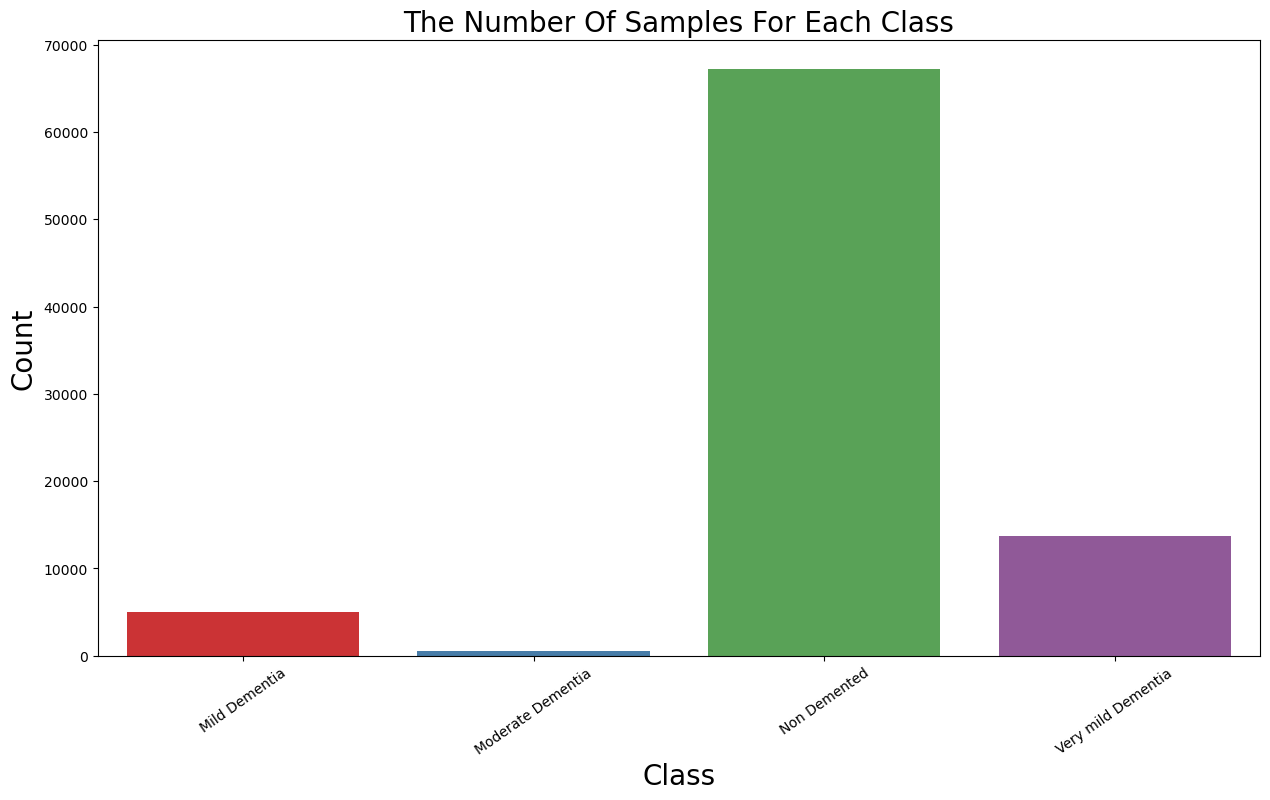

In [4]:
plt.figure(figsize=(15,8))
ax = sns.countplot(x=df.label,palette='Set1')
ax.set_xlabel("Class",fontsize=20)
ax.set_ylabel("Count",fontsize=20)
plt.title('The Number Of Samples For Each Class',fontsize=20)
plt.grid(False)
plt.xticks(rotation=35)
plt.show()

C:\Users\sanja\AppData\Local\Temp\ipykernel_5968\1748014159.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=df.label,palette='Set1')


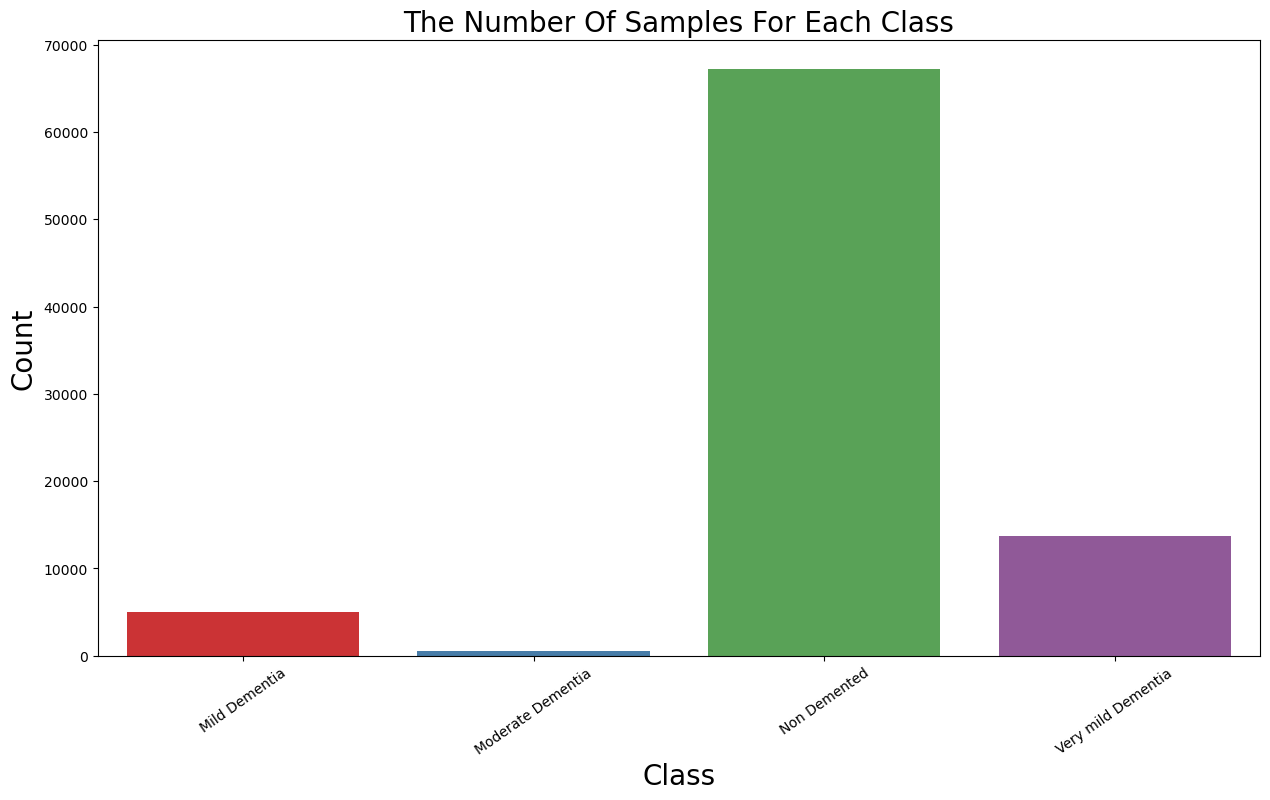

In [5]:
plt.figure(figsize=(15,8))
ax = sns.countplot(x=df.label,palette='Set1')
ax.set_xlabel("Class",fontsize=20)
ax.set_ylabel("Count",fontsize=20)
plt.title('The Number Of Samples For Each Class',fontsize=20)
plt.grid(False)
plt.xticks(rotation=35)
plt.show()

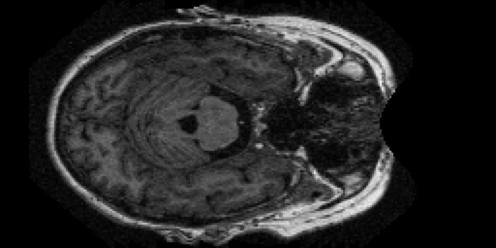

In [6]:
PIL.Image.open(str(non_demented[0]))

In [7]:
print(len(non_demented))
print(len(mild_demented))
print(len(moderate_demented))
print(len(very_mild_demented))

67222
5002
488
13725


In [8]:
# non_demented=non_demented[0:488]
# mild_demented=mild_demented[0:488]
# very_mild_demented=very_mild_demented[0:488]

In [9]:
encoder= OneHotEncoder()
encoder.fit([[0],[1],[2],[3]])

OneHotEncoder()

In [ ]:
data = []
result = []
for s in non_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[0]]).toarray())
        
for s in mild_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[1]]).toarray())

for s in moderate_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[2]]).toarray())

for s in very_mild_demented:
    img = Image.open(s)
    img = img.resize((128,128))
    img = np.array(img)
    if(img.shape == (128,128,3)):
        data.append(np.array(img))
        result.append(encoder.transform([[3]]).toarray())

In [ ]:
X=np.array(data)

In [ ]:
X.shape

In [ ]:
y=np.array(result)
y=y.reshape(X.shape[0],4)
y=np.argmax(y, axis=1)
y

In [ ]:
#Performing over-sampling of the data, since the classes are imbalanced

# import imblearn
# smote = imblearn.over_sampling.SMOTE(random_state=42)
# X, y = smote.fit_resample(X.reshape(-1, 128 * 128 * 3), y)
# X = X.reshape(-1, 128,128, 3)
# print(X.shape, y.shape)

#Performing over-sampling of the data, since the classes are imbalanced

# import imblearn
# smote = imblearn.over_sampling.SMOTE(random_state=42)
# train_images, train_labels = smote.fit_resample(train_images.reshape(-1, 176 * 176 * 3), train_labels)
# train_images = train_images.reshape(-1, 176,176, 3)
# print(train_images.shape, train_labels.shape)

In [ ]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42, shuffle = True)

In [ ]:
X_train.shape

In [ ]:
X_test.shape

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def unet_classification(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck
    bn = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(p4)
    bn = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(bn)

    # Decoder
    u6 = layers.UpSampling2D((2, 2))(bn)
    u6 = layers.Concatenate()([u6, c4])
    c6 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c6)

    u7 = layers.UpSampling2D((2, 2))(c6)
    u7 = layers.Concatenate()([u7, c3])
    c7 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c7)

    u8 = layers.UpSampling2D((2, 2))(c7)
    u8 = layers.Concatenate()([u8, c2])
    c8 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c8)

    u9 = layers.UpSampling2D((2, 2))(c8)
    u9 = layers.Concatenate()([u9, c1])
    c9 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(c9)

    # Global classification head
    gap = layers.GlobalAveragePooling2D()(c9)
    outputs = layers.Dense(num_classes, activation='softmax')(gap)

    model = models.Model(inputs, outputs)
    return model

# Example usage:
input_shape = (128, 128, 1)  # adjust to your EEG input shape
num_classes = y_train.shape[1]  # keep same as one-hot encoding
model = unet_classification(input_shape, num_classes)

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


In [ ]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
from keras.callbacks import EarlyStopping
early_stopping=EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=0,
    mode="auto",
    baseline=None,
    restore_best_weights=True,
    start_from_epoch=0,
)

In [ ]:
history= model.fit(X_train,y_train, validation_split=0.2,epochs=5,callbacks=[early_stopping],batch_size=128)

In [ ]:
model.evaluate(X_test,y_test)

In [ ]:
%matplotlib inline 
plt.plot(history.history['accuracy'],label='train')
plt.plot(history.history['val_accuracy'],label='validation')
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history['loss'],label='train')
plt.plot(history.history['val_loss'],label='validation')
plt.legend()
plt.show()

In [ ]:
#classes names 
class_name = {0: "Mild Dementia",1: "Moderate Dementia" , 2: "Non Demented", 3: "Very mild Dementia"}

In [ ]:
test_scores = model.evaluate(X_test,y_test)
test_scores

In [ ]:
predicted_test_labels = model.predict(X_test)
res = model.predict(X_test)
predicted_test_labels =  np.argmax(predicted_test_labels,axis= 1 )
predicted_test_labels[1]

In [ ]:
ypred = []
for i in res:
  temp = np.argmax(i)
  ypred.append(temp)
ypred = np.array(ypred)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score

accuracy_score(y_test,ypred)

In [ ]:
cf = confusion_matrix(y_true = y_test ,y_pred =  ypred)
plt.figure(figsize=(8, 6), dpi=80, facecolor='w', edgecolor='k')

# ax = sns.heatmap(cf, cmap='Blues', annot=True, fmt='d', xticklabels=class_name, yticklabels=class_name)

# plt.title('Alzheimer\'s Disease Diagnosis')
# plt.xlabel('Prediction')
# plt.ylabel('Truth')
# plt.show(ax)


x = ConfusionMatrixDisplay(cf)
x.plot()

In [ ]:
print(classification_report(y_true = y_test ,y_pred =  ypred))